# 03 – Roof Crops for Labeling

## 1. Goal
Our model classifies **one roof surface** at a time: PV yes / no. For this we need one small image per roof surface.
In this notebook we
- download the data of two **training municipalities**: Rapperswil-Jona (SG, next to Uznach) and Lutry (VD, next to Pully).
  Uznach and Pully are never used for training, only for testing.
- cut out one image per roof surface from SWISSIMAGE (everything outside the roof surface is black)
- draw a sample of roof surfaces **once**, store it as a fixed selection (`data/labels/selection_<municipality>.csv`, versioned in git)
  and save the images of this selection so that we can label them by hand in the next notebook. Both team machines create their crops from the same selection.

## 2. Inputs / Outputs
| | |
| --- | --- |
| **Inputs** | `data/raw/` (from notebook 01), `data/interim/roofs_*.gpkg`, `data/interim/pv_register_*.gpkg`, `data/labels/selection_*.csv` and `data/labels/labels_*.csv` (if they already exist) |
| **Outputs** | `data/interim/roofs_rapperswil-jona.gpkg`, `data/interim/roofs_lutry.gpkg`, SWISSIMAGE tiles of both, `data/labels/selection_<municipality>.csv` (fixed selection, commit it!), `data/processed/crops/<municipality>/unsorted/*.png` |

In [1]:
import os
import requests
import numpy as np
import pandas as pd
import geopandas as gpd
import matplotlib.pyplot as plt
import rasterio
import rasterio.features
from shapely.geometry import box

## 3. Analysis
### 3.1 Data of the training municipalities
Same steps as in notebook 01. The newest flight year is the same as in the neighbouring control municipality:
2025 for Rapperswil-Jona, 2023 for Lutry.

In [2]:
municipalities = gpd.read_file("../data/raw/swissBOUNDARIES3D_1_5_LV95_LN02.gpkg", layer="tlm_hoheitsgebiet")

rapperswil = municipalities[municipalities["bfs_nummer"] == 3340]
lutry = municipalities[municipalities["bfs_nummer"] == 5606]

print(rapperswil[["name", "bfs_nummer", "einwohnerzahl"]])
print(lutry[["name", "bfs_nummer", "einwohnerzahl"]])

                name  bfs_nummer  einwohnerzahl
271  Rapperswil-Jona        3340          28779
       name  bfs_nummer  einwohnerzahl
1404  Lutry        5606          10751


In [3]:
roofs_rapperswil = gpd.read_file("../data/raw/SOLKAT_DACH.gpkg", layer="SOLKAT_CH_DACH", mask=rapperswil)
roofs_lutry = gpd.read_file("../data/raw/SOLKAT_DACH.gpkg", layer="SOLKAT_CH_DACH", mask=lutry)

print("Rapperswil-Jona:", len(roofs_rapperswil), "roof surfaces")
print("Lutry:", len(roofs_lutry), "roof surfaces")

roofs_rapperswil.to_file("../data/interim/roofs_rapperswil-jona.gpkg")
roofs_lutry.to_file("../data/interim/roofs_lutry.gpkg")

Rapperswil-Jona: 20565 roof surfaces
Lutry: 10456 roof surfaces


In [4]:
plants = pd.read_csv("../data/raw/ElectricityProductionPlant.csv")
pv = plants[plants["SubCategory"] == "subcat_2"]
pv = gpd.GeoDataFrame(pv, geometry=gpd.points_from_xy(pv["_x"], pv["_y"]), crs="EPSG:2056")

pv_rapperswil = gpd.clip(pv, rapperswil)
pv_lutry = gpd.clip(pv, lutry)

print("Rapperswil-Jona:", len(pv_rapperswil), "PV plants")
print("Lutry:", len(pv_lutry), "PV plants")

pv_rapperswil.to_file("../data/interim/pv_register_rapperswil-jona.gpkg")
pv_lutry.to_file("../data/interim/pv_register_lutry.gpkg")

Rapperswil-Jona: 723 PV plants
Lutry: 458 PV plants


Download the SWISSIMAGE tiles (same function as in notebook 01). Rapperswil-Jona is bigger, so this takes a few minutes.

In [5]:
def download(url, filename):
    if not os.path.exists(filename):
        print("downloading", filename)
        r = requests.get(url, timeout=60)
        with open(filename, "wb") as f:
            f.write(r.content)


def download_tiles(roofs, year, folder):
    os.makedirs(folder, exist_ok=True)
    roof_area = roofs.union_all()
    xmin, ymin, xmax, ymax = roofs.total_bounds

    for e in range(int(xmin // 1000), int(xmax // 1000) + 1):
        for n in range(int(ymin // 1000), int(ymax // 1000) + 1):
            tile = box(e * 1000, n * 1000, e * 1000 + 1000, n * 1000 + 1000)
            if tile.intersects(roof_area):
                name = f"swissimage-dop10_{year}_{e}-{n}"
                url = f"https://data.geo.admin.ch/ch.swisstopo.swissimage-dop10/{name}/{name}_0.1_2056.tif"
                download(url, f"{folder}/{name}.tif")

In [6]:
download_tiles(roofs_rapperswil, 2025, "../data/raw/swissimage_rapperswil-jona")
download_tiles(roofs_lutry, 2023, "../data/raw/swissimage_lutry")

print(len(os.listdir("../data/raw/swissimage_rapperswil-jona")), "tiles for Rapperswil-Jona")
print(len(os.listdir("../data/raw/swissimage_lutry")), "tiles for Lutry")

downloading ../data/raw/swissimage_rapperswil-jona/swissimage-dop10_2025_2702-1232.tif
downloading ../data/raw/swissimage_rapperswil-jona/swissimage-dop10_2025_2702-1233.tif
downloading ../data/raw/swissimage_rapperswil-jona/swissimage-dop10_2025_2703-1231.tif
downloading ../data/raw/swissimage_rapperswil-jona/swissimage-dop10_2025_2703-1232.tif
downloading ../data/raw/swissimage_rapperswil-jona/swissimage-dop10_2025_2703-1233.tif
downloading ../data/raw/swissimage_rapperswil-jona/swissimage-dop10_2025_2704-1231.tif
downloading ../data/raw/swissimage_rapperswil-jona/swissimage-dop10_2025_2704-1232.tif
downloading ../data/raw/swissimage_rapperswil-jona/swissimage-dop10_2025_2704-1233.tif
downloading ../data/raw/swissimage_rapperswil-jona/swissimage-dop10_2025_2704-1234.tif
downloading ../data/raw/swissimage_rapperswil-jona/swissimage-dop10_2025_2705-1230.tif
downloading ../data/raw/swissimage_rapperswil-jona/swissimage-dop10_2025_2705-1231.tif
downloading ../data/raw/swissimage_rappersw

**Observation:** Tiles are stored in a raw folder ordered by municipality.
### 3.2 Cut out one roof surface
How the function works:
1. Take the bounding box of the roof surface plus 2 m border.
2. A roof can lie on up to 4 tiles (at the tile corners). So we read the box from every tile that touches it
   and combine the parts with `np.maximum` (outside of a tile, `boundless=True` gives black pixels).
3. Make a mask of the roof polygon and set all pixels outside the roof surface to black.

In [7]:
def make_crop(roof, folder, year):
    xmin, ymin, xmax, ymax = roof.bounds
    xmin, ymin, xmax, ymax = xmin - 2, ymin - 2, xmax + 2, ymax + 2
    width = int((xmax - xmin) * 10)    # 10 pixels per metre
    height = int((ymax - ymin) * 10)

    # which tiles are touched by the corners of the box?
    filenames = set()
    for x in [xmin, xmax]:
        for y in [ymin, ymax]:
            filenames.add(f"{folder}/swissimage-dop10_{year}_{int(x // 1000)}-{int(y // 1000)}.tif")

    image = np.zeros((3, height, width), dtype=np.uint8)
    for filename in filenames:
        if os.path.exists(filename):
            src = rasterio.open(filename)
            window = src.window(xmin, ymin, xmax, ymax)
            part = src.read(window=window, boundless=True, out_shape=(3, height, width))
            image = np.maximum(image, part)

    transform = rasterio.transform.from_bounds(xmin, ymin, xmax, ymax, width, height)
    inside = rasterio.features.geometry_mask([roof], (height, width), transform, invert=True)
    image[:, inside == False] = 0

    return image.transpose(1, 2, 0)    # (height, width, 3) for matplotlib

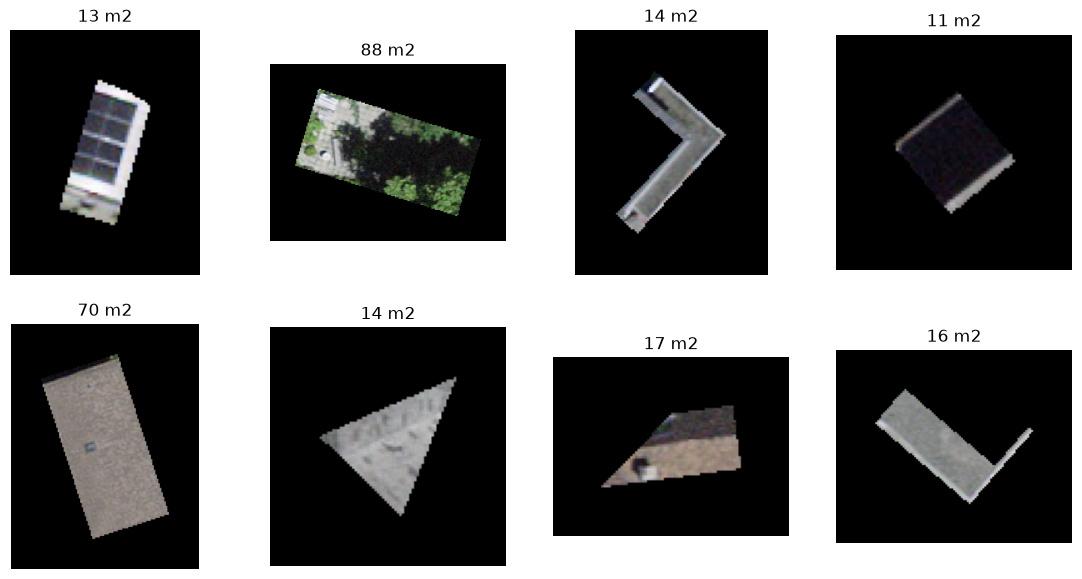

In [8]:
roofs_uznach = gpd.read_file("../data/interim/roofs_uznach.gpkg")
examples = roofs_uznach.sample(8, random_state=0)

fig, axes = plt.subplots(2, 4, figsize=(14, 7))
for ax, (i, roof) in zip(axes.flatten(), examples.iterrows()):
    ax.imshow(make_crop(roof.geometry, "../data/raw/swissimage_uznach", 2025))
    ax.set_title(f"{roof['FLAECHE']:.0f} m2")
    ax.axis("off")
plt.show()

**Observation:** The output shows nicely cutted pictures. As the resolution isn't really good, it is sometimes quite hard to try to detect PVs (see picture with 11 m2). Also the shape of some roofs are quite weird (14 m2). But with all of the tiles, we should be capable to get a good training/test set.

### 3.3 Select roof surfaces for labeling
We can't label all roofs by hand, so we take a sample. If we took a random sample, only about 10 % of the roofs would have PV.
That's why we use the BFE register to get more PV examples:
- **register pool**: roof surfaces of buildings with a PV plant in the register that was built before the flight.
  Not every one of these surfaces really has PV (often only the south side has panels), we check this by hand.
- **other pool**: roof surfaces of buildings without any PV plant in the register.

We only use roof surfaces with at least 10 m2, smaller ones are too small for a PV plant.

Sample size: 500 + 500 per training municipality, 200 + 200 per control municipality (test set).

In [9]:
def select_roofs(roofs, pv, flight_year, n):
    pv_year = pd.to_datetime(pv["BeginningOfOperation"]).dt.year
    egid_pv_before_flight = pv[pv_year <= flight_year]["EGID"]

    roofs = roofs[roofs["FLAECHE"] >= 10]
    register_pool = roofs[roofs["GWR_EGID"].isin(egid_pv_before_flight)]
    other_pool = roofs[roofs["GWR_EGID"].isin(pv["EGID"]) == False]
    print(len(register_pool), "roofs in register pool,", len(other_pool), "roofs in other pool")

    selected = pd.concat([
        register_pool.sample(n, random_state=42),
        other_pool.sample(n, random_state=42),
    ])
    return selected

### 3.4 Save the crops
Every image is saved as `<DF_UID>.png` (DF_UID = ID of the roof surface in sonnendach) into the folder `unsorted`.
The images are mixed, so you can't see from the file name which pool a roof comes from.

**Fixed selection:** We work on two machines and the images are not in git. `sample(random_state=42)` alone is not enough: if the PV register differs slightly between machines, the pools differ and a completely different sample is drawn. That's why the selected roofs are stored once in `data/labels/selection_<municipality>.csv` (versioned), and the crops are always created from this file. Existing municipalities never get a new sample. For a new municipality: add it to `CROP_SETTINGS`, run the cell and commit the selection file **before** labeling.

In [ ]:
# Create crops from a fixed, versioned selection.
# The selection is stored in data/labels/selection_<municipality>.csv (in git).
# Both machines create their images only from these files -> identical crops everywhere.
import shutil

CROP_SETTINGS = {
    # municipality:    (folder with orthophotos,                  flight year, n per pool)
    "rapperswil-jona": ("../data/raw/swissimage_rapperswil-jona", 2025, 500),
    "lutry":           ("../data/raw/swissimage_lutry",           2023, 500),
    "uznach":          ("../data/raw/swissimage_uznach",          2025, 200),
    "pully":           ("../data/raw/swissimage_pully",           2023, 200),
}

# Accidental label from commit 42f5f30: this roof is not part of the original Lutry selection
ACCIDENTAL_LABELS = {"lutry": [19318210]}


def remove_accidental_labels(municipality):
    labels_file = f"../data/labels/labels_{municipality}.csv"
    bad_ids = ACCIDENTAL_LABELS.get(municipality, [])
    if not bad_ids or not os.path.exists(labels_file):
        return
    labels = pd.read_csv(labels_file)
    bad = labels["DF_UID"].isin(bad_ids)
    if bad.any():
        labels[~bad].to_csv(labels_file, index=False)
        print(f"{municipality}: removed {bad.sum()} accidental label(s)")


def get_selection(municipality, roofs, flight_year, n):
    selection_file = f"../data/labels/selection_{municipality}.csv"
    labels_file = f"../data/labels/labels_{municipality}.csv"

    # 1) a fixed selection exists -> always use it
    if os.path.exists(selection_file):
        return pd.read_csv(selection_file)

    # 2) already labeled -> the labeled IDs are the binding selection
    if os.path.exists(labels_file):
        ids = pd.read_csv(labels_file)["DF_UID"]
    # 3) new municipality -> draw a sample once
    else:
        pv = gpd.read_file(f"../data/interim/pv_register_{municipality}.gpkg")
        ids = select_roofs(roofs, pv, flight_year, n)["DF_UID"]

    selection = pd.DataFrame({"DF_UID": sorted(ids.astype(int).unique())})
    selection.to_csv(selection_file, index=False)
    print(f"{municipality}: selection saved ({len(selection)} roofs) -> please commit!")
    return selection


def sync_crops(municipality):
    folder_tiles, year, n = CROP_SETTINGS[municipality]
    folder_out = f"../data/processed/crops/{municipality}"
    unsorted = f"{folder_out}/unsorted"
    for sub in ["unsorted", "pv", "no_pv"]:
        os.makedirs(f"{folder_out}/{sub}", exist_ok=True)

    if not os.path.isdir(folder_tiles) or not os.listdir(folder_tiles):
        raise FileNotFoundError(f"No orthophotos in {folder_tiles} - run download_tiles first")

    roofs = gpd.read_file(f"../data/interim/roofs_{municipality}.gpkg")
    selection = get_selection(municipality, roofs, year, n)
    selected = roofs[roofs["DF_UID"].isin(selection["DF_UID"])]

    missing = set(selection["DF_UID"]) - set(selected["DF_UID"])
    if missing:
        raise ValueError(f"{municipality}: {len(missing)} IDs of the selection are missing in roofs_{municipality}.gpkg")

    # move images that are not part of the selection aside (don't delete them)
    wanted = {f"{uid}.png" for uid in selection["DF_UID"]}
    stale = [f for f in os.listdir(unsorted) if f.endswith(".png") and f not in wanted]
    if stale:
        os.makedirs(f"{folder_out}/not_in_selection", exist_ok=True)
        for f in stale:
            shutil.move(f"{unsorted}/{f}", f"{folder_out}/not_in_selection/{f}")

    # create missing images (existing ones stay unchanged)
    created = 0
    for _, roof in selected.iterrows():
        path = f"{unsorted}/{roof['DF_UID']}.png"
        if not os.path.exists(path):
            plt.imsave(path, make_crop(roof.geometry, folder_tiles, year))
            created += 1

    print(f"{municipality}: {len(wanted)} in selection, {created} created, "
          f"{len(stale)} moved to not_in_selection")


for municipality in CROP_SETTINGS:
    remove_accidental_labels(municipality)
    sync_crops(municipality)

**Observation:** _comment on output_

## 4. Conclusion & Open Points
- _summary_
- Next step (notebook 04): sort the images in `unsorted` by hand into `pv` and `no_pv`.